# LaTeX drawing and a trainable CNN–quantum model

This CPU example preserves the existing text and Matplotlib workflows, exports
editable LaTeX, and displays figures directly in Notebook output cells.
The hybrid drawing is an **explicit architecture description** matching the model
below; it is not an automatically traced graph.

Prerequisites: install this FlagQuantum checkout and Jupyter/IPython. Source export
needs no additional tools. To display the LaTeX figure, install **Tectonic** (or
TeX Live) and **Poppler** (`pdftocairo` for SVG, or `pdftoppm` for PNG) on the
Notebook kernel's PATH. For example, macOS users can run
`brew install tectonic poppler`; TeX Live plus Poppler also works on Linux.
Tectonic may download standard TeX resources on first use. FlagQuantum itself
never downloads or installs rendering executables.

In [1]:
from pathlib import Path

import torch
from torch import nn
from IPython.display import display

import flagquantum as fq
from flagquantum.drawer import draw_hybrid

torch.manual_seed(7)
torch.set_num_threads(1)

## Existing draw behavior

The default still returns terminal text. Matplotlib still returns `(figure, axes)`;
its optional dependency is installed with `pip install "flagquantum[viz]"`.

0: ───H───╭●─┤
1: ───────╰X─┤


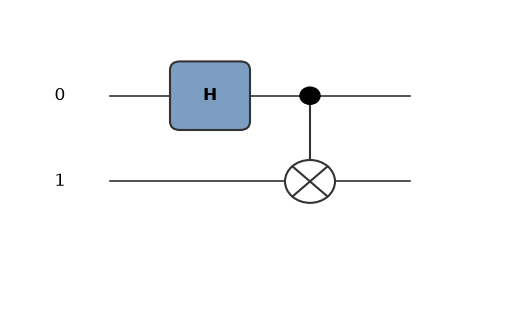

In [2]:
bell = fq.Circuit(2).h(0).cx(0, 1)
print(bell.draw())

from matplotlib import pyplot as plt

mpl_figure, axes = bell.draw(format="mpl")
display(mpl_figure)
plt.close(mpl_figure)

## Editable source and inline rendering

`format="latex"` returns a lazy `LatexFigure`. Reading `.source` or writing `.tex`
does not compile anything. Returning the object as the final expression of a cell
invokes the Notebook MIME protocol: SVG when `pdftocairo` is available, otherwise
PNG. `display=True` explicitly displays the same object.

In [3]:
symbolic = fq.Circuit(3)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"x_{qubit}"))
symbolic.cx(0, 1).cx(1, 2)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"theta_{qubit}"))

circuit_figure = symbolic.draw(format="latex")
print(circuit_figure.source)

\documentclass[border=12pt]{standalone}
\usepackage{flaghybrid}
\begin{document}
\begin{tikzpicture}
\begin{yquant}
qubit {$q_{\idx}$} q[3];
box {$R_y(x_{0})$} q[0];
box {$R_y(x_{1})$} q[1];
box {$R_y(x_{2})$} q[2];
cnot q[1] | q[0];
cnot q[2] | q[1];
box {$R_y(\theta_{0})$} q[0];
box {$R_y(\theta_{1})$} q[1];
box {$R_y(\theta_{2})$} q[2];
\end{yquant}
\end{tikzpicture}
\end{document}



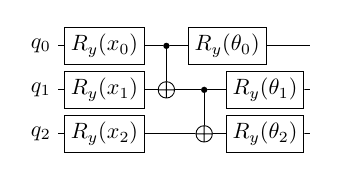

In [4]:
circuit_figure

## A real differentiable hybrid model

A small CNN maps a 1×8×8 input to three angle features. Three trainable quantum
rotations follow the entangling gates. The head maps the three Z expectations to
two class logits. One synthetic CPU training step demonstrates gradients through
all three components; it is not an accuracy or performance benchmark.

In [5]:
class HybridCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 3, kernel_size=3, padding=1),
            nn.Tanh(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.theta = nn.Parameter(0.1 * torch.randn(3))
        self.head = nn.Linear(3, 2)

    def quantum_features(self, features: torch.Tensor) -> torch.Tensor:
        circuit = fq.Circuit(3)
        for qubit in range(3):
            circuit.ry(qubit, features[qubit])
        circuit.cx(0, 1).cx(1, 2)
        for qubit in range(3):
            circuit.ry(qubit, self.theta[qubit])
        return torch.stack([
            circuit.expectation_z(qubit).reshape(()) for qubit in range(3)
        ])

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.encoder(images)
        quantum = torch.stack([self.quantum_features(row) for row in features])
        return self.head(quantum)


model = HybridCNN()
images = torch.randn(4, 1, 8, 8)
labels = torch.tensor([0, 1, 0, 1])
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
optimizer.zero_grad()
loss = nn.functional.cross_entropy(model(images), labels)
loss.backward()

for name, parameter in (
    ("CNN", model.encoder[0].weight),
    ("quantum", model.theta),
    ("head", model.head.weight),
):
    assert parameter.grad is not None
    assert torch.isfinite(parameter.grad).all()
    assert parameter.grad.abs().sum() > 0
    print(f"{name} gradient norm: {parameter.grad.norm().item():.6f}")

before = model.theta.detach().clone()
optimizer.step()
assert not torch.equal(before, model.theta.detach())
print(f"Synthetic training loss: {loss.detach().item():.6f}")

CNN gradient norm: 0.003033
quantum gradient norm: 0.001278
head gradient norm: 0.209511
Synthetic training loss: 0.707551


## Display the matching quantum–classical architecture

The symbolic gate sequence matches `quantum_features`. The labels explicitly
declare three CNN features and two head outputs. Solid arrows carry data, the
double line carries readout values, and dashed paths illustrate parameter updates.
Rendering the diagram never calls the model's `forward` or optimizer.

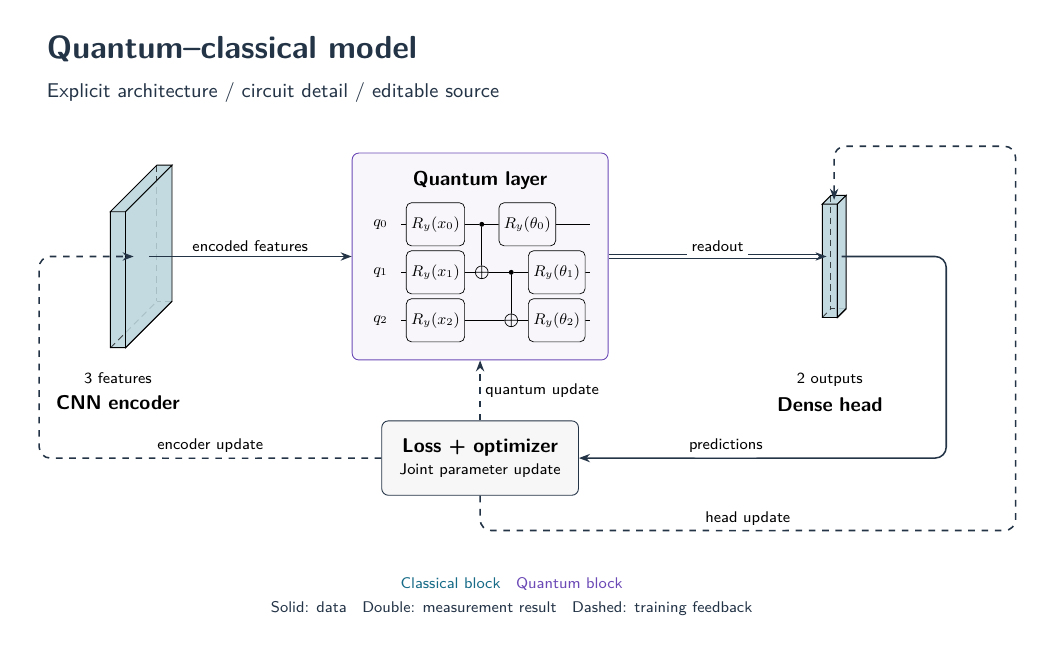

In [6]:
hybrid_figure = draw_hybrid(
    symbolic,
    encoder="CNN encoder",
    encoder_features=3,
    head="Dense head",
    head_outputs=2,
    training=True,
)
hybrid_figure

## Save source, PDF, PNG and a portable Overleaf project

`.export_bundle()` includes a standalone main document, the matching `.sty/.tex`
runtime and component licenses. Existing files with different content are refused.
Rendering bytes are cached on the figure, so saving after inline display reuses
its compilation. SVG can also be saved when `pdftocairo` is installed.

In [7]:
output = Path("latex_exports")
output.mkdir(exist_ok=True)
hybrid_figure.save_source(output / "hybrid.tex")
main_file = hybrid_figure.export_bundle(output / "overleaf")
hybrid_figure.save(output / "hybrid.pdf")
hybrid_figure.save(output / "hybrid.png")
print(f"Portable project: {main_file}")
print("Saved hybrid.tex, hybrid.pdf and hybrid.png")

Portable project: latex_exports/overleaf/figure.tex
Saved hybrid.tex, hybrid.pdf and hybrid.png


## Support boundary

The LaTeX circuit backend accepts native Circuit/CircuitIR and serialized IR.
Noise channels, explicit matrices, dynamic control and batched gate parameters
require additional rendering rules and currently raise explicit errors. Terminal
measurement requests are annotated without inventing collapse gates.
The explicit three-stage hybrid view does not claim arbitrary model tracing,
interactive graph editing, hardware execution or distributed scaling.